# Can we recognise a distorted song as the catalogue grows?
Run all cells on CPU from the repository root or the notebooks directory. The first experiment runs a real identification search on a small release sample. The main table recomputes accuracy from **16,450 held-out predictions per catalogue**. GPU timings and training comparisons are saved measurements. The README gives the commands to repeat the full experiments on the released data. The last section before the conclusion runs our own LSH, k-means and DBSCAN code on the released fingerprints; it downloads about 160 MB once and takes about a minute.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'reports/report-evidence').is_dir())
evidence = root/'reports/report-evidence'
def read(name):
    return json.loads((evidence/name).read_text())
original = read('original-retrieval.json')
repeat = read('retrieval-rerun.json')
head = read('projection.json')['families']
cluster = read('clustering.json')
methods = ['exact','lsh','ivf']

## A working lookup
Select the highest cosine-scoring reference window and return its track ID. This example uses one held-out distorted clip for each of 32 sampled Medium tracks and their reference windows. The smaller candidate pool makes this a demonstration.

In [2]:
with np.load(evidence/'example.npz') as a:
    best = (a['queries'] @ a['references'].T).argmax(1)
    print(f"{(a['ref_ids'][best] == a['truth']).sum()}/{len(best)} clips identified in the 32-track example.")

32/32 clips identified in the 32-track example.


## Which part improved recognition?
Frozen MuQ produces a 1,024-dimensional representation. A head trained on clean/distorted pairs maps it to a 256-dimensional unit vector. Holding the query clips and exact retrieval fixed measures the effect of this trained projection, including its change of dimension. The interval resamples songs to keep repeated queries together.

In [3]:
for family, r in head.items():
    assert r['gained'] - r['lost'] == r['trained_correct'] - r['raw_correct']
    lo, hi = r['paired_song_bootstrap95_pp']
    print(f"{family}: {r['raw_correct']}/{r['queries']} → {r['trained_correct']}/{r['queries']}; "
          f"{r['delta_pp']:+.2f} points (95% CI {lo:.2f} to {hi:.2f})")

queries: 6920/7458 → 7315/7458; +5.30 points (95% CI 4.75 to 5.85)
queries_tiktok: 5217/8992 → 8411/8992; +35.52 points (95% CI 34.52 to 36.56)


## The same clips against more distractors
All three methods use the same head, held-out clips and best-window track rule. Angular LSH uses 10 bits, 64 tables and three extra probes. Spherical k-means IVF uses 256 centroids and probes 16. The earlier Medium accuracy-first setting was explored after the initial comparison; it was frozen for catalogue growth. The original paired timings below measure warm GPU lookup, excluding decoding and fingerprint extraction.

In [4]:
rows = []
with np.load(evidence/'predictions.npz') as p:
    for subset in ['medium','large']:
        for method in methods:
            row = {'catalogue': subset, 'method': method}
            for family in ['standard','tiktok']:
                truth = p[f'{family}_truth']
                found = p[f'{subset}_{family}_{method}'] == truth
                assert found.sum() == original[subset]['correct'][family][method] == repeat[subset]['families'][family][method]
                row[family] = 100 * found.mean()
            row['original median ms'] = original[subset]['median_lookup_ms'][method]
            row['repeat median ms'] = repeat[subset]['median_lookup_ms'][method]
            row['original batch q/s'] = original[subset]['batch128_queries_per_s'][method]
            rows.append(row)
    for family in ['standard','tiktok']:
        hit = [p[f'{s}_{family}_exact'] == p[f'{family}_truth'] for s in ['medium','large']]
        print(f'{family}: {(hit[0] & ~hit[1]).sum()} exact matches lost, {(~hit[0] & hit[1]).sum()} gained')
table = pd.DataFrame(rows)
table.round(4)

standard: 130 exact matches lost, 0 gained
tiktok: 316 exact matches lost, 0 gained


,catalogue,method,standard,tiktok,original median ms,repeat median ms,original batch q/s
0,medium,exact,98.0826,93.5387,0.1730,0.1808,376036.0995
1,medium,lsh,98.0826,93.5387,0.0815,0.0901,71854.2682
2,medium,ivf,97.5329,92.7714,0.0699,0.0771,433446.8113
3,large,exact,96.3395,90.0245,0.5849,0.5910,95267.4932
4,large,lsh,96.4736,90.2024,0.2533,0.2666,7056.8022
5,large,ivf,95.9909,89.4573,0.1238,0.1302,89420.3010


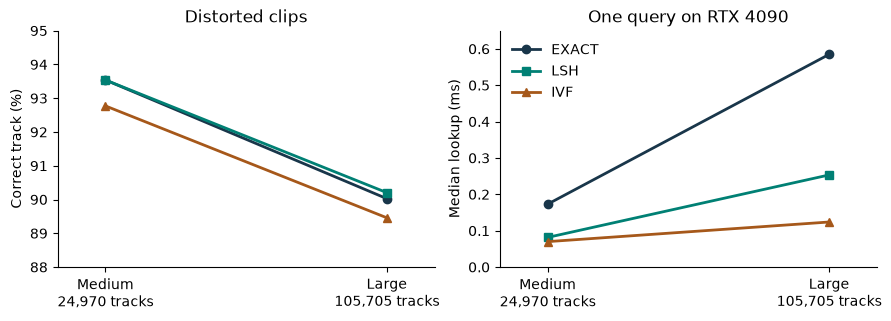

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.1), layout='constrained')
for method, color, mark in zip(methods, ['#19364a','#008074','#a6581a'], ['o','s','^']):
    v = table[table.method == method]
    for ax, column in zip(axes, ['tiktok', 'original median ms']):
        ax.plot([0,1], v[column], marker=mark, color=color, label=method.upper(), linewidth=2)
for ax in axes:
    ax.set_xticks([0,1], ['Medium\n24,970 tracks', 'Large\n105,705 tracks'])
    ax.margins(x=.17)
    ax.spines[['right','top']].set_visible(False)
axes[0].set(ylabel='Correct track (%)', title='Distorted clips', ylim=(88,95))
axes[1].set(ylabel='Median lookup (ms)', title='One query on RTX 4090', ylim=(0,.65))
axes[1].legend(frameon=False)
fig.savefig(root/'reports/figures/report-catalogues.pdf', bbox_inches='tight')
plt.show()

## What did clustering find?
The merged CPU IVF ran with a 16,384-window fitting sample and assigned every catalogue window. The same 128 queries per family were selected on both sizes. A separate all-centroid check compared the best cosine to exact on eight queries per family per catalogue. These CPU checks and the full GPU comparison use different fitting and timing protocols.

In [6]:
pd.DataFrame([{'catalogue':s, 'family':f, **row} for s in ['medium','large']
              for f,row in cluster[s]['families'].items()]).round(4)

,catalogue,family,queries,exact_correct,ivf_correct,track_agreement,mean_window_share,all_probe_checks
0,medium,queries,128,126,124,126,0.0623,8
1,medium,queries_tiktok,128,123,121,126,0.0626,8
2,large,queries,128,124,124,126,0.0624,8
3,large,queries_tiktok,128,118,115,123,0.0616,8


DBSCAN on Small can link two archive IDs that share a recording. The example below includes source and returned IDs, window positions and the hashes of their decoded 24 kHz mono samples. Strict-ID scoring counts them separately. The neighbourhood threshold was cosine 0.9 with two points (including the window itself).

In [7]:
d = cluster['small_dbscan']
print(f"{d['linked_pairs']} linked pairs; {d['noise_share']:.1%} of windows labelled noise.")
print(d['families'])
case = d['example']
assert case['source_id'] != case['returned_id'] and len(set(case['pcm_sha256'].values())) == 1
pd.Series(case)

69 linked pairs; 82.6% of windows labelled noise.
{'queries': {'strict_errors': 34, 'linked_errors': 5, 'queries': 2000}, 'queries_tiktok': {'strict_errors': 200, 'linked_errors': 6, 'queries': 2000}}


family                                                        queries_tiktok
query_row                                                                115
source_id                                                              86761
returned_id                                                            74348
query_start_s                                                      11.282917
reference_start_s                                                       10.0
artist_a                                                    Marco Trovatello
title_a                                                             Be Sweet
artist_b                                                    Marco Trovatello
title_b                                                             Be Sweet
track_a                                                                74348
track_b                                                                86761
strongest_window_cosine                                                  1.0

## Our algorithms, run on the released fingerprints
The cells below run the implementations we wrote: random-hyperplane LSH with multi-probe (`afp.lsh`), spherical k-means with an inverted-file index and the Davies-Bouldin index (`afp.cluster`), and DBSCAN with a cosine neighbourhood (`afp.related`). They use the v0.3 Medium release (110,320 reference windows) and, for DBSCAN, the v0.2 Small release. Files are downloaded once into the git-ignored `data/release/` and checked against their SHA-256 sums (about 160 MB). The section takes about a minute on a laptop CPU.

Queries are a random sample of 1,000 per family from the release files. These include development queries, so the accuracies differ slightly from the held-out table above. Times are per query on this CPU. Our LSH loops over queries in Python while exhaustive search is one batched matrix product, so CPU times are not comparable with the GPU timings above; the share of windows scored does not depend on the hardware.

In [8]:
import hashlib
import io
import time
import zipfile
from urllib.request import urlopen

from afp.cluster import IVFIndex, davies_bouldin
from afp.lsh import AngularLSH
from afp.related import dbscan, describe_pairs, shared_track_pairs
from afp.retrieval import search

release_dir = root / 'data/release'
release_dir.mkdir(parents=True, exist_ok=True)
download_base = 'https://github.com/nickiliak/02807_computational_tools_ds/releases/download'


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def fetch(tag, asset, expected, local=None):
    path = release_dir / (local or asset)
    if not (path.exists() and sha256(path) == expected):
        with urlopen(f'{download_base}/{tag}/{asset}') as response, open(path, 'wb') as out:
            out.write(response.read())
        if sha256(path) != expected:
            path.unlink()
            raise ValueError(f'checksum mismatch for {asset}')
    return path


medium_zip = fetch('v0.3-fingerprints', 'fma-medium-fingerprints.zip',
                   '98a82079857b54488ed809360f4a6cae21f37be8afc573b4097cf2874fd22eef')
small_refs = fetch('v0.2-fingerprints', 'references.npz',
                   'fb749ede9dd8cf363aac209d5d83ce74ca6e00a73a23ad8477d9d7ecb310fbba', 'small-references.npz')
small_manifest = fetch('v0.2-fingerprints', 'manifest.csv',
                       '8fe1d544d30f2a161aa4109451750621f4d6558629f4c9293f129644101ca643', 'small-manifest.csv')
print('release files present and checksum-verified:', medium_zip.name, small_refs.name, small_manifest.name)

release files present and checksum-verified: fma-medium-fingerprints.zip small-references.npz small-manifest.csv


In [9]:
prefix = 'data/medium/data/processed/fingerprints/'


def read_npz(archive, name):
    return dict(np.load(io.BytesIO(archive.read(prefix + name))))


with zipfile.ZipFile(medium_zip) as archive:
    refs = read_npz(archive, 'references.npz')
    query_files = {kind: read_npz(archive, f'{kind}.npz') for kind in ['queries', 'queries_tiktok']}
R, T = refs['vectors'], refs['track_id']
rng = np.random.default_rng(0)
sample = {}
for kind, q in query_files.items():
    pick = rng.choice(len(q['vectors']), 1000, replace=False)
    sample[kind] = (q['vectors'][pick], q['track_id'][pick])
print(f'{len(R):,} reference windows from {len(set(T)):,} tracks; 1,000 sampled queries per family')

110,320 reference windows from 24,970 tracks; 1,000 sampled queries per family


### Locality-sensitive hashing
Ten random-hyperplane bits form a table key, 64 tables are OR-ed, and three extra probes visit the buckets reached by flipping the query's least certain bits. Candidates are reranked by exact cosine. The table compares the track found with exhaustive search.

In [10]:
lsh = AngularLSH(R, T, bits=10, tables=64)
rows = []
for kind, (Q, truth) in sample.items():
    start = time.perf_counter()
    exact, _ = search(R, T, Q)
    exact_ms = (time.perf_counter() - start) / len(Q) * 1e3
    start = time.perf_counter()
    found = lsh.search(Q, probe_budget=3)
    lsh_ms = (time.perf_counter() - start) / len(Q) * 1e3
    rows.append({'family': kind, 'method': 'exhaustive cosine', 'top-1': np.mean(exact == truth),
                 'windows scored': 1.0, 'ms/query (CPU)': exact_ms})
    rows.append({'family': kind, 'method': 'LSH, 10 bits x 64 tables, 3 probes', 'top-1': np.mean(found.track == truth),
                 'windows scored': found.candidates.mean() / len(R), 'ms/query (CPU)': lsh_ms})
pd.DataFrame(rows).round(3)

,family,method,top-1,windows scored,ms/query (CPU)
0,queries,exhaustive cosine,0.978,1.000,0.356
1,queries,"LSH, 10 bits x 64 tables, 3 probes",0.977,0.081,7.256
2,queries_tiktok,exhaustive cosine,0.947,1.000,0.297
3,queries_tiktok,"LSH, 10 bits x 64 tables, 3 probes",0.934,0.081,6.646


### k-means as an inverted-file index
Spherical k-means (k-means++ seeding, unit-length centroids) is fitted on a 16,384-window sample with 256 centroids; every window is assigned to its nearest centroid. A query is compared only with the windows in its 16 closest clusters. The Davies-Bouldin index summarises how well separated the clusters are (lower is better).

In [11]:
index = IVFIndex.build(R, k=256, sample=16384, seed=2807)
rows = []
for kind, (Q, truth) in sample.items():
    start = time.perf_counter()
    nearest, compared = index.search(Q, nprobe=16)
    rows.append({'family': kind, 'method': 'k-means IVF, 256 centroids, 16 probed',
                 'top-1': np.mean(T[nearest] == truth), 'windows scored': compared.mean() / len(R),
                 'ms/query (CPU)': (time.perf_counter() - start) / len(Q) * 1e3})
inside = np.random.default_rng(1).choice(len(R), 16384, replace=False)
print(f'Davies-Bouldin index of the 256 clusters (16,384-window sample): '
      f'{davies_bouldin(R[inside], index.labels[inside]):.2f}; '
      f'the largest cluster holds {np.bincount(index.labels).max() / len(R):.2%} of the windows')
pd.DataFrame(rows).round(3)

Davies-Bouldin index of the 256 clusters (16,384-window sample): 3.80; the largest cluster holds 0.90% of the windows


,family,method,top-1,windows scored,ms/query (CPU)
0,queries,"k-means IVF, 256 centroids, 16 probed",0.973,0.063,0.597
1,queries_tiktok,"k-means IVF, 256 centroids, 16 probed",0.937,0.062,0.704


### DBSCAN: tracks that share audio
DBSCAN runs on the Small release windows with cosine similarity of at least 0.9 and two points as the core condition. Unique music has no such neighbour and becomes noise; a cluster that holds windows of two or more tracks links them. The assertion checks that this run reproduces the counts stored in the report evidence.

In [12]:
small = np.load(small_refs)
small_vectors, small_tracks = small['vectors'], small['track_id']
manifest = pd.read_csv(small_manifest)
labels, core = dbscan(small_vectors, min_similarity=0.9, min_points=2)
pairs = describe_pairs(shared_track_pairs(small_vectors, small_tracks, labels), manifest)
stored = cluster['small_dbscan']
noise = np.mean(labels == -1)
print(f"{noise:.1%} of {len(labels):,} windows are noise; {len(pairs)} track pairs are linked; "
      f"{pairs['same_artist'].mean():.0%} of the pairs share an artist.")
assert len(pairs) == stored['linked_pairs'] and abs(noise - stored['noise_share']) < 1e-9
pairs[['artist_a', 'title_a', 'artist_b', 'title_b', 'max_similarity']].head(8)

82.6% of 35,292 windows are noise; 69 track pairs are linked; 97% of the pairs share an artist.


,artist_a,title_a,artist_b,title_b,max_similarity
0,Squire Tuck,Ukulele Rising,Squire Tuck,Squire Tuck - Ukulele Rising,1.0
1,Blue Dot Sessions,Master,Blue Dot Sessions,Master,1.0
2,Cheese N Pot-C,Funky Motion (Clean Version),Cheese N Pot-C,Funky Motion,1.0
3,Marco Trovatello,Be Sweet,Marco Trovatello,Be Sweet,1.0
4,Blue Dot Sessions,Micro,Blue Dot Sessions,Micro,1.0
5,Squire Tuck,Ukulele Blues,Squire Tuck,Squire Tuck - Ukulele Blues,1.0
6,SPCZ,Legend,SPCZ,Legend,1.0
7,Maxwell Powers,Saturday,Maxwell Powers,Saturday,1.0


On this sample both approximate indexes score under a tenth of the windows and stay within about a point and a half of exhaustive search, and DBSCAN reproduces the linked pairs reported above. The GPU timings and the held-out counts earlier in the notebook remain the evidence for speed and for the Large catalogue.

## Conclusion
On Large, LSH preserved recognition closest to exhaustive lookup, IVF gave the lowest single-query latency, and exact search handled the most queries per second in batches of 128. The distortion benchmark uses generated clips and the same Medium queries on both catalogues. A prospective phone test would measure what changes when the sound passes through a loudspeaker, room and microphone.